In [110]:
from langgraph.graph import StateGraph, START, END
from typing import List, Dict, Any, TypedDict, Optional, Literal
from langchain_cohere import ChatCohere
from langchain_core.messages import HumanMessage
from dotenv import load_dotenv

load_dotenv()
llm = ChatCohere(model="command-a-03-2025")

In [111]:
class QuadraticWorkflow(TypedDict):
    a: float
    b: float
    c: float

    equation: str
    discriminant: float
    result: str

In [112]:
# equation: \(ax^2 + bx + c = 0\)
def show_equation(state: QuadraticWorkflow):
    equation = f"{state['a']}x^2 + {state['b']}x + {state['c']} = 0"
    return {'equation': equation}

In [113]:
# calculate the discriminant
def calculate_discriminant(state: QuadraticWorkflow):
    discriminant = state['b']**2 - 4*state['a']*state['c']
    return {'discriminant': discriminant}

In [114]:
# Node1-> Real roots discriminant > 0
def calculate_real_roots(state: QuadraticWorkflow):
    
    root1 = (-state['b'] + state['discriminant']**0.5) / (2*state['a'])
    root2 = (-state['b'] - state['discriminant']**0.5) / (2*state['a'])

    result = f"There are 2 distinct real solutions: {root1} and {root2}."
    return {'result': result} 

In [115]:
 # Node 2-> repeated root discriminant = 0
def calculate_repeated_root(state: QuadraticWorkflow):
    root = -state['b'] / (2*state['a'])
    result = f"There is exactly 1 real solution (repeated root): {root}."
    return {'result': result}

In [116]:
# Node3 -> no real roots discriminant < 0
def calculate_no_real_roots(state: QuadraticWorkflow):
    result = "There are no real solutions."
    return {'result': result}


In [117]:
# determine the nature of the roots based on the discriminant
def check_condition(state: QuadraticWorkflow) -> Literal['calculate_real_roots', 'calculate_repeated_root', 'calculate_no_real_roots']:
    if state['discriminant'] > 0:
        return 'calculate_real_roots'
    elif state['discriminant'] == 0:
        return 'calculate_repeated_root'
    else:
        return 'calculate_no_real_roots'

In [123]:
# create a graph
graph = StateGraph(QuadraticWorkflow)

In [124]:
# add nodes
graph.add_node('show_equation', show_equation)
graph.add_node('calculate_discriminant', calculate_discriminant)
#graph.add_node('check_condition', check_condition)
graph.add_node('calculate_real_roots', calculate_real_roots)
graph.add_node('calculate_repeated_root', calculate_repeated_root)
graph.add_node('calculate_no_real_roots', calculate_no_real_roots)


In [125]:
# add edges
graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calculate_discriminant')

# conditional edges based on the nature of the roots
graph.add_conditional_edges('calculate_discriminant', check_condition)

graph.add_edge('calculate_real_roots', END)
graph.add_edge('calculate_repeated_root', END)
graph.add_edge('calculate_no_real_roots', END)

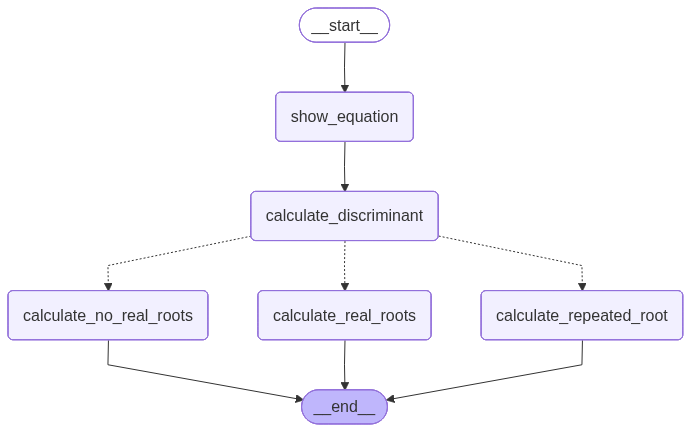

In [129]:
# compile the graph
workflow = graph.compile()
workflow

In [131]:
initial_state = {
    'a': 4,
    'b': -5,
    'c': -4
}
final_state = workflow.invoke(initial_state)
print(final_state)

{'a': 4, 'b': -5, 'c': -4, 'equation': '4x^2 + -5x + -4 = 0', 'discriminant': 89, 'result': 'There are 2 distinct real solutions: 1.8042476415070754 and -0.5542476415070754.'}
